# "Lived Space": figures

Reproduces the figures in Rohrbacher, *"Lived Space": A Computational Study of Setting in Fiction*.

`data/space_counts_per_book.csv` contains for every book, the number of sentences the classifier assigned to each type of setting
(`perceived_space` = *gestimmter Raum*, `action_space` = *Aktionsraum*, `visual_space` = *Anschauungsraum*, `descriptive_space`, `no_space`).
Corpus metadata: Rohrbacher (2025), https://doi.org/10.5281/zenodo.15714828.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

DATA = Path("../data")
FIGS = Path("../figures")
FIGS.mkdir(exist_ok=True)

SPACE_TYPES = ["perceived_space", "action_space", "visual_space", "descriptive_space", "no_space"]
SETTING_TYPES = SPACE_TYPES[:-1]

GENRES = {
    "Historische Kriminalromane und -fälle": "hist crime",
    "Historische Romane und Erzählungen": "hist novels",
    "Horror": "horror",
    "Humor, Satire": "satire",
    "Jugendliteratur": "young adult (YA)",
    "Krimis, Thriller, Spionage": "crime",
    "Märchen, Sagen, Legenden": "fairy tales",
    "Phantastische Literatur": "spec fic",
    "Romane, Novellen und Erzählungen": "novels, novellas",
    "Romanhafte Biographien": "bio fic",
    "Science Fiction": "sci fi",
    "Spannung und Abenteuer": "adventure",
}

sns.set_theme(context="paper", style="whitegrid")

def save(fig, name):
    fig.savefig(FIGS / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIGS / f"{name}.pdf", bbox_inches="tight")

In [2]:
books = pd.read_csv(DATA / "space_counts_per_book.csv")
books["all_space"] = books[SETTING_TYPES].sum(axis=1)
corpus = books[books["year"].between(1780, 1940)]
print(f"{len(books)} books in total, {len(corpus)} published 1780-1940")
books.head()

4784 books in total, 4601 published 1780-1940


,author_last,author_first,title,year,genre,filename,perceived_space,action_space,visual_space,descriptive_space,no_space,num_sents,all_space
0,a Sancta Clara,Abraham,Wunderlicher Traum von einem großen Narrennest,1703,"Humor, Satire",Abraham_a_Sancta_Clara_-_Wunderlicher_Traum_vo...,13,38,0,6,502,559,57
1,a Sancta Clara,Abraham,Fabeln und Parabeln,1954,"Märchen, Sagen, Legenden",Abraham_a_Sancta_Clara_-_Fabeln_und_Parabeln.txt,38,117,6,13,710,884,174
2,Achleitner,Arthur,Der Finanzer,1916,"Romane, Novellen und Erzählungen",Arthur_Achleitner_-_Der_Finanzer.txt,124,483,23,27,1066,1723,657
3,Achleitner,Arthur,Das Schloß im Moor,1903,"Romane, Novellen und Erzählungen",Arthur_Achleitner_-_Das_Schloß_im_Moor.txt,126,564,25,32,2713,3460,747
4,Achleitner,Arthur,Familie Lugmüller,1896,"Romane, Novellen und Erzählungen",Arthur_Achleitner_-_Familie_Lugmüller.txt,127,373,9,27,1431,1967,536


## Corpus overview

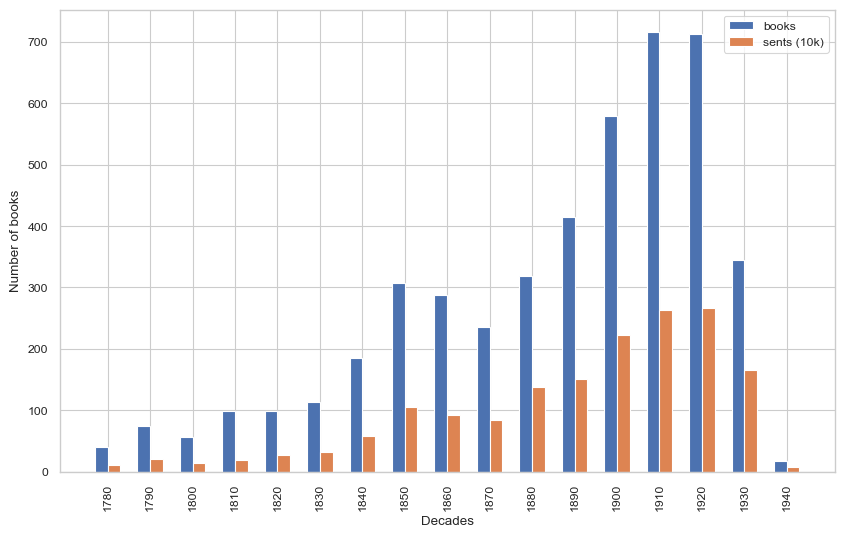

In [3]:
decades = (corpus.assign(decade=corpus["year"] // 10 * 10)
           .groupby("decade")
           .agg(books=("filename", "size"), sents=("num_sents", "sum")))

x = np.arange(len(decades))
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - 0.15, decades["books"], 0.3, label="books")
ax.bar(x + 0.15, decades["sents"] / 10_000, 0.3, label="sents (10k)")
ax.set_xticks(x, labels=decades.index, rotation=90)
ax.set_xlabel("Decades")
ax.set_ylabel("Number of books")
ax.legend()
save(fig, "corpus_decades")

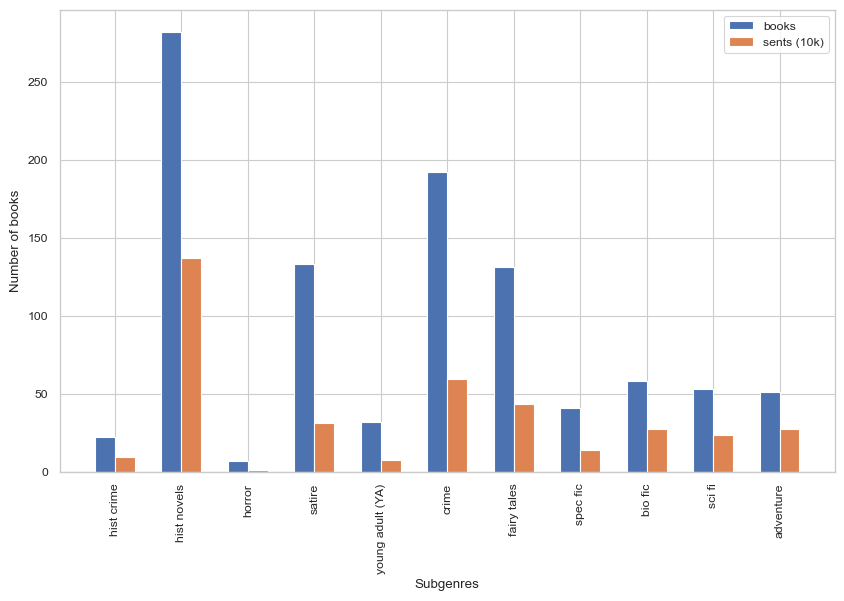

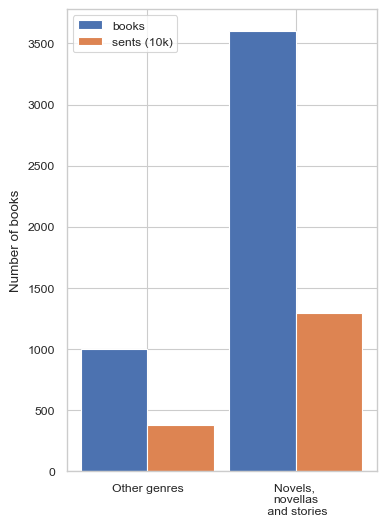

In [4]:
genres = corpus.groupby("genre").agg(books=("filename", "size"), sents=("num_sents", "sum"))
genres.index = genres.index.map(GENRES)
subgenres = genres.drop("novels, novellas")

x = np.arange(len(subgenres))
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - 0.15, subgenres["books"], 0.3, label="books")
ax.bar(x + 0.15, subgenres["sents"] / 10_000, 0.3, label="sents (10k)")
ax.set_xticks(x, labels=subgenres.index, rotation=90)
ax.set_xlabel("Subgenres")
ax.set_ylabel("Number of books")
ax.legend()
save(fig, "corpus_subgenres")

is_novel = genres.index == "novels, novellas"
split = pd.DataFrame({"Other genres": genres[~is_novel].sum(),
                      "Novels, \nnovellas\n and stories": genres[is_novel].sum()}).T

x = np.arange(len(split))
fig, ax = plt.subplots(figsize=(4, 6))
ax.bar(x - 0.225, split["books"], 0.45, label="books")
ax.bar(x + 0.225, split["sents"] / 10_000, 0.45, label="sents (10k)")
ax.set_xticks(x, labels=split.index)
ax.set_ylabel("Number of books")
ax.legend(loc="upper left")
save(fig, "corpus_novels_vs_other")

## Figure 4: types of setting over time

Share of sentences per book, smoothed by pooling each year with the books of the preceding nine years. Bands are 95% bootstrap confidence intervals.

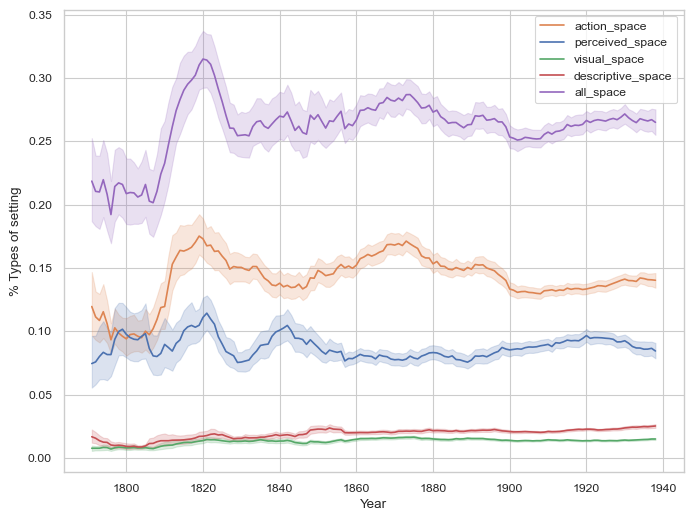

In [5]:
def pooled_window(df, half_window=5):
    df = df.reset_index()
    lo, hi = df["year"].min(), df["year"].max()
    shifted = pd.concat([df.assign(year=df["year"] + 1 + i) for i in range(2 * half_window - 1)])
    return shifted[shifted["year"].isin(range(lo + 2 * half_window, hi))].set_index("year")

plot_types = ["action_space", "perceived_space", "visual_space", "descriptive_space", "all_space"]
sel = corpus[(corpus["year"] > 1780) & (corpus["year"] < 1940)]
ratios = sel.set_index("year")[plot_types].div(sel.set_index("year")["num_sents"], axis=0)
smoothed = pooled_window(ratios)

fig, ax = plt.subplots(figsize=(8, 6))
sns.lineplot(smoothed, palette=["#dd8452", "#4c72b0", "#55a868", "#c44e52", "#9467bd"], dashes=False, ax=ax)
ax.set_xlabel("Year")
ax.set_ylabel("% Types of setting")
save(fig, "fig4_setting_over_time")

## Figure 5: types of setting across genres

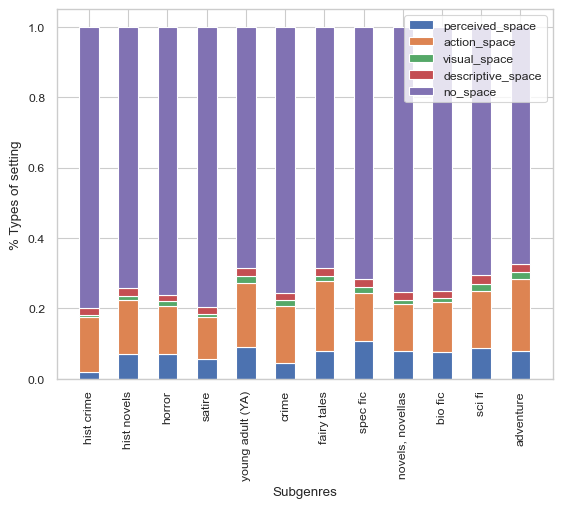

In [6]:
by_genre = books.groupby("genre")[SPACE_TYPES + ["num_sents"]].sum()
by_genre.index = by_genre.index.map(GENRES)
shares = by_genre[SPACE_TYPES].div(by_genre["num_sents"], axis=0)

fig, ax = plt.subplots()
bottom = np.zeros(len(shares))
for space_type in SPACE_TYPES:
    ax.bar(shares.index, shares[space_type], 0.5, label=space_type, bottom=bottom)
    bottom += shares[space_type].values
ax.legend(loc="upper right")
ax.set_xlabel("Subgenres")
ax.set_ylabel("% Types of setting")
ax.tick_params(axis="x", rotation=90)
save(fig, "fig5_setting_by_genre")

In [7]:
(shares.assign(all_space=shares[SETTING_TYPES].sum(axis=1)) * 100).round(1)

,perceived_space,action_space,visual_space,descriptive_space,no_space,all_space
genre,,,,,,
hist crime,2.0,15.5,0.7,2.0,79.8,20.2
hist novels,7.2,15.2,1.2,2.2,74.2,25.8
horror,7.0,13.7,1.5,1.8,76.1,23.9
satire,5.5,12.1,0.9,2.0,79.5,20.5
young adult (YA),8.9,18.3,1.9,2.4,68.5,31.5
crime,4.6,16.0,1.6,2.2,75.6,24.4
fairy tales,8.0,19.8,1.3,2.3,68.5,31.5
spec fic,10.9,13.6,1.7,2.1,71.8,28.2
"novels, novellas",8.0,13.2,1.4,2.1,75.4,24.6
